# 🤖 Umělá inteligence – Student Lab Workbook (Reading Week)

**Téma:** Teorie her, Nashova rovnováha, Algoritmus Minimax a Evoluční dynamika populací

**Cílová skupina:** Magisterské studium (Mgr.)

**Forma výuky:** Samostudium

**Časová dotace:** 100 minut

**Prostředí:** Google Colab / Python 3

---

## 📅 Doporučený harmonogram samostatné práce (100 minut)

* **00:00 – 00:20 (20 min):** Teoretický základ – Nashova rovnováha, Minimax a Vězňovo dilema
* **00:20 – 00:40 (20 min):** Praktická implementace: Výpočet Nashovy rovnováhy a Minimaxu v Pythonu
* **00:40 – 00:70 (30 min):** Evoluční simulátor (`simulation.py`) a experimenty s populacemi (Úkoly 1–3)
* **00:70 – 00:90 (20 min):** Úkol 4: Návrh učící se / adaptivní strategie (Q-Learning)
* **00:90 – 0100 (10 min):** Syntéza poznatků, analytické otázky a sebereflexe

---

## 1. Teoretický základ: Teorie her, Nashova rovnováha a Minimax

V multiagentních systémech se rozhodování agenta odvíjí od očekávaného chování ostatních subjektů. Matice odměn pro dva hráče určuje výnos $R_1(a_1, a_2)$ pro Hráče 1 a $R_2(a_1, a_2)$ pro Hráče 2 při volbě akcí $a_1, a_2 \in \{C, D\}$.

### Matice odměn Vězňova dilematu

Předpokládejme standardní konfiguraci odměn $(T, R, P, S)$, kde platí $T > R > P > S$ a zároveň $2R > T + S$:

* **$T$ (Temptation / Pokušení):** $5$ bodů za jednostrannou zradu
* **$R$ (Reward / Odměna):** $3$ body za oboustrannou spolupráci
* **$P$ (Punishment / Trest):** $1$ bod za oboustrannou zradu
* **$S$ (Sucker's payoff / Prohra):** $0$ bodů za podvedenou spolupráci

| Hráč 1 \ Hráč 2 | C (Spolupráce) | D (Zrada) |
| --- | --- | --- |
| **C (Spolupráce)** | **3 / 3** | **0 / 5** |
| **D (Zrada)** | **5 / 0** | **1 / 1** |

### Nashova rovnováha (Nash Equilibrium)

Profil akcí $(a_1^*, a_2^*)$ představuje **Nashovu rovnováhu**, pokud žádný z hráčů nemůže jednostrannou změnou své strategie dosáhnout vyššího výnosu:


$$\forall a_1: R_1(a_1^*, a_2^*) \ge R_1(a_1, a_2^*)$$

$$\forall a_2: R_2(a_1^*, a_2^*) \ge R_2(a_1^*, a_2)$$

V jednorázovém Vězňově dilematu je profil $(D, D)$ **jedinou ryzí Nashovou rovnováhou**, přestože profil $(C, C)$ přináší oběma vyšší užitek (Pareto optimalita).

### Principy rozhodování: Minimax

Algoritmus **Minimax** minimalizuje maximální možnou ztrátu (resp. maximalizuje garantovaný minimální zisk v nejhorším případě):


$$a_1^{\text{minimax}} = \arg\max_{a_1} \min_{a_2} R_1(a_1, a_2)$$

* Pro volbu **$C$**: Nejhorší možný výsledek nastane, když soupeř zvolí $D \rightarrow \text{zisk} = 0$.
* Pro volbu **$D$**: Nejhorší možný výsledek nastane, když soupeř zvolí $D \rightarrow \text{zisk} = 1$.
* **Minimax rozhodnutí:** Volba $D$, protože $\max(0, 1) = 1$.

---

## 2. Praktická ukázka: Nashova rovnováha a Minimax v Pythonu

V následující buňce si naimplementujeme nástroj pro analytické vyhodnocení matice odměn, nalezení Nashových rovnováh v ryzích strategiích a určení Minimax volby pro libovolnou hru $2 \times 2$.

In [9]:
# [BUŇKA 1] Výpočet Nashovy rovnováhy a Minimaxu pro 2x2 hry
import numpy as np

def analyze_payoff_matrix(R1, R2, action_names=['C', 'D']):
    """
    Analýza matice odměn pro 2 hráče.
    R1: Matice odměn pro Hráče 1 (řádky = Hráč 1, sloupce = Hráč 2)
    R2: Matice odměn pro Hráče 2
    """
    num_actions = len(action_names)
    print("=== MATICE ODMĚN (Hráč 1 / Hráč 2) ===")
    for i in range(num_actions):
        row_str = [f"{R1[i,j]}/{R2[i,j]}" for j in range(num_actions)]
        print(f"{action_names[i]}: " + " | ".join(row_str))
    print("=" * 40)

    # 1. Výpočet Minimax volby pro Hráče 1
    worst_case_R1 = np.min(R1, axis=1) # nejhorší výsledek pro každou akci Hráče 1
    minimax_action_idx = np.argmax(worst_case_R1)
    print(f"🛡️ Minimax analýza pro Hráče 1:")
    for i, a in enumerate(action_names):
        print(f"   Akce '{a}': Garantované minimum = {worst_case_R1[i]} bodů")
    print(f"   -> Minimax volba: '{action_names[minimax_action_idx]}'\n")

    # 2. Hledání Nashových rovnováh v ryzích strategiích
    nash_equilibria = []
    for i in range(num_actions):
        for j in range(num_actions):
            # Je Hráč 1 v nejlepším stavu vůči volbě j Hráče 2?
            is_best_r1 = R1[i, j] == np.max(R1[:, j])
            # Je Hráč 2 v nejlepším stavu vůči volbě i Hráče 1?
            is_best_r2 = R2[i, j] == np.max(R2[i, :])

            if is_best_r1 and is_best_r2:
                nash_equilibria.append((action_names[i], action_names[j]))

    print(f"⚖️ Nalezené Nashovy rovnováhy (Hráč 1, Hráč 2):")
    if nash_equilibria:
        for eq in nash_equilibria:
            print(f"   -> Profil: ({eq[0]}, {eq[1]})")
    else:
        print("   -> Žádná ryzí Nashova rovnováha neexistuje.")

# Matice odměn Vězňova dilematu
R1_pd = np.array([[3, 0],
                  [5, 1]]) # Hráč 1
R2_pd = np.array([[3, 5],
                  [0, 1]]) # Hráč 2

analyze_payoff_matrix(R1_pd, R2_pd)

=== MATICE ODMĚN (Hráč 1 / Hráč 2) ===
C: 3/3 | 0/5
D: 5/0 | 1/1
🛡️ Minimax analýza pro Hráče 1:
   Akce 'C': Garantované minimum = 0 bodů
   Akce 'D': Garantované minimum = 1 bodů
   -> Minimax volba: 'D'

⚖️ Nalezené Nashovy rovnováhy (Hráč 1, Hráč 2):
   -> Profil: (D, D)


---

## 3. Evoluční simulátor dynamiky populací (`simulation.py`)

Představme si populaci jedinců, kteří mezi sebou opakovaně hrají Vězňovo dilema a na základě získaných bodů se rozmnožují.

* Může v takové simulaci existovat strategie, která přežije ve všech případech?
* Existuje skupina strategií, kterou nelze napadnout nově příchozí strategií (Evolučně stabilní strategie – ESS)?

### Princip simulátoru:

1. **Konfigurace:** Počáteční stav populace načítá soubor `config.json` (pokud neexistuje, vytvoří se výchozí s 10 instancemi od každé dostupné strategie).
2. **Generace a setkání:** V každé generaci odehraje každý jedinec $E$ náhodných zápasů (defaultně $E = 10$) proti náhodně vybraným oponentům. Zápas je iterované Vězňovo dilema o délce 200 kol.
3. **Ruletová selekce (Fitness Propagation):** Pravděpodobnost postupu/rozmnožení jedince do další generace je úměrná jeho kumulovanému skóre:

$$P(\text{jedinec}_i) = \frac{\text{Skóre}_i}{\sum_{j} \text{Skóre}_j}$$


4. **Vizualizace:** Výstupem je graf počtu jedinců a průměrného skóre v jednotlivých generacích.

In [10]:
# [BUŇKA 2] Příprava prostředí a vytvoření modulů strategií
import os
import json

os.makedirs('strategies', exist_ok=True)
with open('strategies/__init__.py', 'w') as f: pass

# Definice základních strategií
strategies_code = {
"always_cooperate.py": """
class AlwaysCooperate:
    @staticmethod
    def author_name(): return "Pilat"
    @staticmethod
    def strategy_name(): return "Always Cooperate"
    def reset(self): pass
    def last_move(self, my, other): pass
    def play(self): return 'C'
def create_strategy(): return AlwaysCooperate()
""",
"always_defect.py": """
class AlwaysDefect:
    @staticmethod
    def author_name(): return "Pilat"
    @staticmethod
    def strategy_name(): return "Always Defect"
    def reset(self): pass
    def last_move(self, my, other): pass
    def play(self): return 'D'
def create_strategy(): return AlwaysDefect()
""",
"random_strat.py": """
import random
class RandomStrat:
    @staticmethod
    def author_name(): return "Pilat"
    @staticmethod
    def strategy_name(): return "Random"
    def reset(self): pass
    def last_move(self, my, other): pass
    def play(self): return 'C' if random.randint(0,1) == 0 else 'D'
def create_strategy(): return RandomStrat()
""",
"titfortat.py": """
class TitForTat:
    @staticmethod
    def author_name(): return "Pilat"
    @staticmethod
    def strategy_name(): return "Tit for Tat"
    def __init__(self): self.reset()
    def reset(self): self.last_op = None
    def last_move(self, my, other): self.last_op = other
    def play(self): return self.last_op if self.last_op else 'C'
def create_strategy(): return TitForTat()
"""
}

for filename, code in strategies_code.items():
    with open(f'strategies/{filename}', 'w') as f:
        f.write(code.strip())

print("✅ Základní moduly strategií byly uloženy do 'strategies/'.")

✅ Základní moduly strategií byly uloženy do 'strategies/'.


In [12]:
# [BUŇKA 3] Implementace modulu simulation.py s podporou config.json a ruletové selekce
import collections
import copy
import importlib
import json
import os
import random
import sys
import matplotlib.pyplot as plt
import numpy as np

# Herní matice odměn (Vězňovo dilema)
DEFAULT_REWARD_MATRIX = {
    ('C', 'C'): (3, 3),
    ('C', 'D'): (0, 5),
    ('D', 'C'): (5, 0),
    ('D', 'D'): (1, 1)
}
REWARD_MATRIX = dict(DEFAULT_REWARD_MATRIX)

def play_game(s1, s2, iters=200):
    s1.reset()
    s2.reset()
    sc1, sc2 = 0, 0
    for _ in range(iters):
        m1, m2 = s1.play(), s2.play()
        r1, r2 = REWARD_MATRIX.get((m1, m2), (-1, -1))
        if r1 < 0 or r2 < 0:
            return 0, 0
        sc1 += r1
        sc2 += r2
        s1.last_move(m1, m2)
        s2.last_move(m2, m1)
    return sc1, sc2

def create_default_config(strat_modules, config_file='config.json'):
    config = {sm: 10 for sm in strat_modules}
    with open(config_file, 'w') as f:
        json.dump(config, f, indent=2)
    return config

def run_simulation(config_file='config.json', max_gen=10, encounters=10, custom_matrix=None, seed=None, title=None):
    global REWARD_MATRIX
    # [UPRAVA] bez custom_matrix se vraci standardni matice (drive zustala Stag Hunt i pro dalsi behy)
    REWARD_MATRIX = dict(custom_matrix) if custom_matrix else dict(DEFAULT_REWARD_MATRIX)

    # [UPRAVA] seed pro reprodukovatelne vysledky
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Nacitani strategii
    strat_modules = []
    for f in os.listdir('strategies'):
        if f.endswith('.py') and not f.startswith('__'):
            strat_modules.append(f'strategies.{f[:-3]}')

    if not os.path.exists(config_file):
        config = create_default_config(strat_modules, config_file)
    else:
        with open(config_file) as f:
            config = json.load(f)

    pop = []
    strategies = {}
    importlib.invalidate_caches()
    for k, v in config.items():
        pop += v * [k]
        # [UPRAVA] reload, aby se zmeny v souborech strategii projevily bez restartu kernelu
        module = importlib.reload(sys.modules[k]) if k in sys.modules else importlib.import_module(k)
        strategies[k] = module.create_strategy()
        # [UPRAVA] ucici se strategie dostanou matici odmen, se kterou simulace bezi
        if hasattr(strategies[k], 'set_reward_matrix'):
            strategies[k].set_reward_matrix(REWARD_MATRIX)

    pop_size = len(pop)
    str_counts = []
    str_scores = []

    for g in range(max_gen):
        scores = pop_size * [0]
        for s1_idx, s in enumerate(pop):
            s1 = strategies[s]
            for _ in range(encounters + 1):
                s2_idx = np.random.randint(0, pop_size)
                s2 = copy.deepcopy(strategies[pop[s2_idx]])
                sc1, sc2 = play_game(s1, s2, iters=200)
                scores[s1_idx] += sc1
                scores[s2_idx] += sc2

        counter = collections.Counter(pop)
        counts = {k: counter[k] for k in strategies.keys()}
        str_counts.append(counts)

        # Prumerne skore na strategii
        avg_scores = {}
        for k in strategies.keys():
            k_scores = [sc for sc, st in zip(scores, pop) if st == k]
            avg_scores[k] = np.mean(k_scores) if k_scores else 0
        str_scores.append(avg_scores)

        # Ruletova selekce (vyber s opakovanim)
        total_score = np.sum(scores)
        if total_score > 0:
            probs = np.array(scores) / total_score
        else:
            probs = np.ones(pop_size) / pop_size

        pop = list(np.random.choice(pop, size=pop_size, p=probs))

    # [UPRAVA] textovy souhrn pro odpovedi na otazky
    final_counter = collections.Counter(pop)
    print(f"{'Strategie':<34}{'Start':>6}{'Gen ' + str(max_gen - 1):>8}{'Konec':>7}{'Prum. skore (gen 0 -> posl.)':>32}")
    for k in strategies.keys():
        print(f"{strategies[k].strategy_name():<34}{str_counts[0][k]:>6}{str_counts[-1][k]:>8}{final_counter[k]:>7}"
              f"{str_scores[0][k]:>18.0f} -> {str_scores[-1][k]:.0f}")

    # Vykresleni vysledku
    plt.figure(figsize=(12, 8))
    if title:
        plt.suptitle(title, fontsize=14)
    plt.subplot(2, 1, 1)
    for s in strategies.keys():
        plt.plot([sc[s] for sc in str_counts], label=strategies[s].strategy_name(), marker='o')
    plt.title("Vývoj počtu jedinců v populaci napříč generacemi")
    plt.ylabel("Počet jedinců")
    plt.grid(True)
    plt.legend()

    plt.subplot(2, 1, 2)
    for s in strategies.keys():
        plt.plot([sc[s] for sc in str_scores], label=strategies[s].strategy_name(), marker='s')
    plt.title("Průměrný zisk bodů na jedince v generaci")
    plt.xlabel("Generace")
    plt.ylabel("Průměrné skóre")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()
    return str_counts, str_scores, strategies

print("✅ Evoluční simulátor načten.")

✅ Evoluční simulátor načten.


---

## 4. Samostatné úkoly a experimenty

V této části budete provádět experimenty se simulátorem, měnit nastavení v `config.json` a upravovat herní matici odměn.

### 📝 Úkol 1: Směsi strategií – Invaze zrádců vs. Odolnost spolupráce

Otestujte dvě odlišné konfigurace populace a zasaďte výsledky do kontextu Nashovy rovnováhy a evolučně stabilní strategie (ESS):

1. **Scénář A:** Populace složená ze $45 \times$ `Always Cooperate` (AC) a $5 \times$ `Always Defect` (AD).
2. **Scénář B:** Populace složená ze $45 \times$ `Tit for Tat` (TFT) a $5 \times$ `Always Defect` (AD).

🧪 Spouštím Scénář A (45x AC + 5x AD)...
Strategie                          Start   Gen 9  Konec    Prum. skore (gen 0 -> posl.)
Always Cooperate                      45       0      0             11920 -> 0
Always Defect                          5      50     50             20120 -> 4400


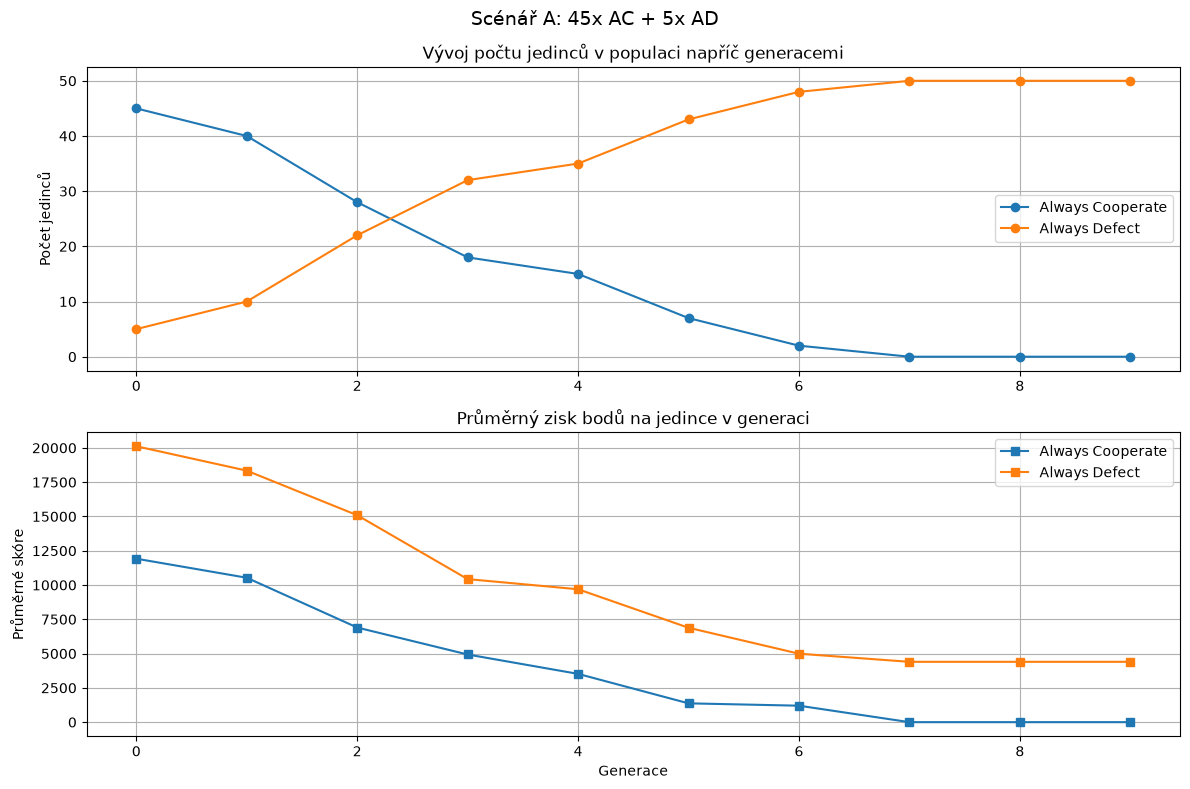

🧪 Spouštím Scénář B (45x TFT + 5x AD)...
Strategie                          Start   Gen 9  Konec    Prum. skore (gen 0 -> posl.)
Tit for Tat                           45      50     50             12358 -> 13200
Always Defect                          5       0      0              4359 -> 0


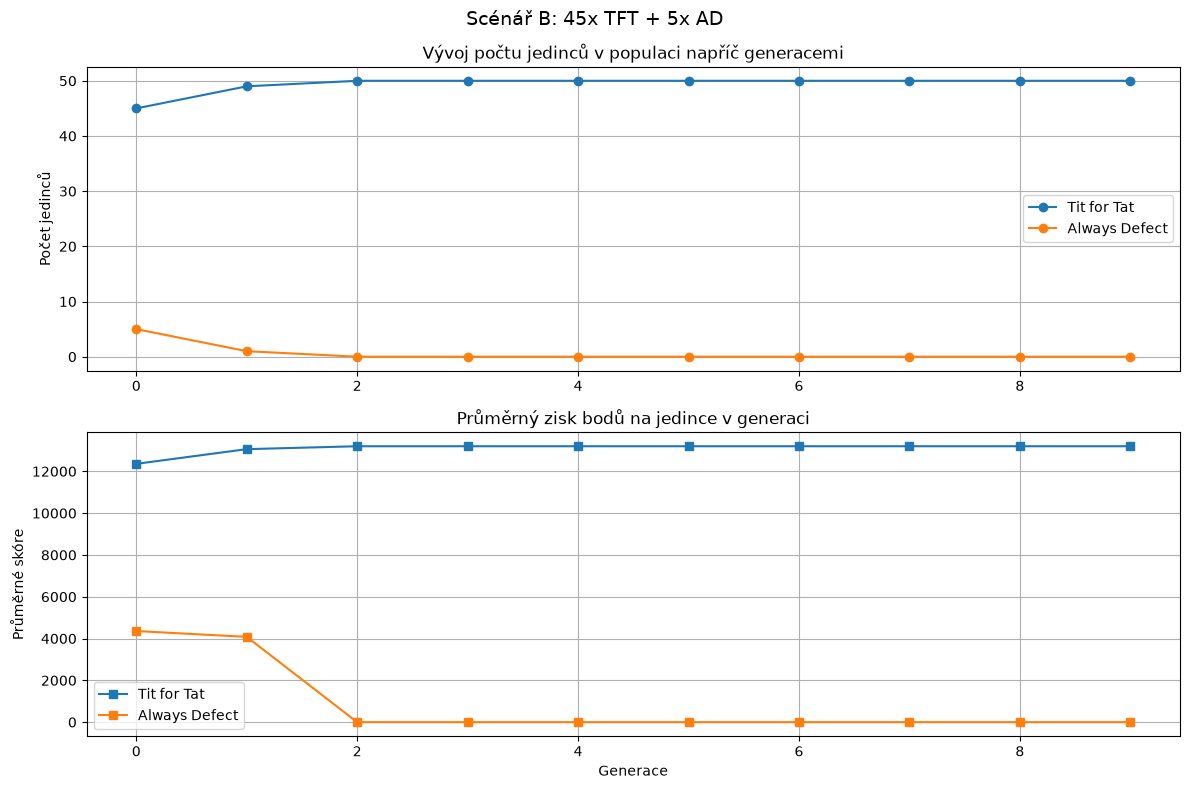

([{'strategies.titfortat': 45, 'strategies.always_defect': 5},
  {'strategies.titfortat': 49, 'strategies.always_defect': 1},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0},
  {'strategies.titfortat': 50, 'strategies.always_defect': 0}],
 [{'strategies.titfortat': np.float64(12357.8),
   'strategies.always_defect': np.float64(4359.2)},
  {'strategies.titfortat': np.float64(13060.816326530612),
   'strategies.always_defect': np.float64(4080.0)},
  {'strategies.titfortat': np.float64(13200.0), 'strategies.always_defect': 0},
  {'strategies.titfortat': np.float64(13200.0), 'strategies.always_defect': 0}

In [13]:
# [BUŇKA 4] ÚKOL 1 – Testování invaze zrádců (AD) do AC vs. TFT

# --- SCÉNÁŘ A: 45x AC + 5x AD ---
config_a = {
    'strategies.always_cooperate': 45,
    'strategies.always_defect': 5
}
with open('config_scenario_a.json', 'w') as f:
    json.dump(config_a, f)

print("🧪 Spouštím Scénář A (45x AC + 5x AD)...")
run_simulation('config_scenario_a.json', max_gen=10, seed=42, title='Scénář A: 45x AC + 5x AD')

# --- SCÉNÁŘ B: 45x TFT + 5x AD ---
config_b = {
    'strategies.titfortat': 45,
    'strategies.always_defect': 5
}
with open('config_scenario_b.json', 'w') as f:
    json.dump(config_b, f)

print("🧪 Spouštím Scénář B (45x TFT + 5x AD)...")
run_simulation('config_scenario_b.json', max_gen=10, seed=42, title='Scénář B: 45x TFT + 5x AD')

---

### 📝 Úkol 2: Nalezení prostředí pro přežití vlastní strategie

Vytvořte novou strategii `TitForTwoTats` (TF2T) a najděte dvě různé populace:

1. **Příznivou populaci:** Skupina strategií, kde `TF2T` přežije nebo zcela převládne.
2. **Nepříznivou populaci:** Skupina strategií, kde `TF2T` brzy vymře.

🧪 Testuji Příznivé prostředí pro TF2T...
Strategie                          Start   Gen 9  Konec    Prum. skore (gen 0 -> posl.)
Tit For Two Tats                      10      26     30             12960 -> 13338
Always Cooperate                      20      12     11             13080 -> 12700
Tit for Tat                           20      12      9             13440 -> 13400


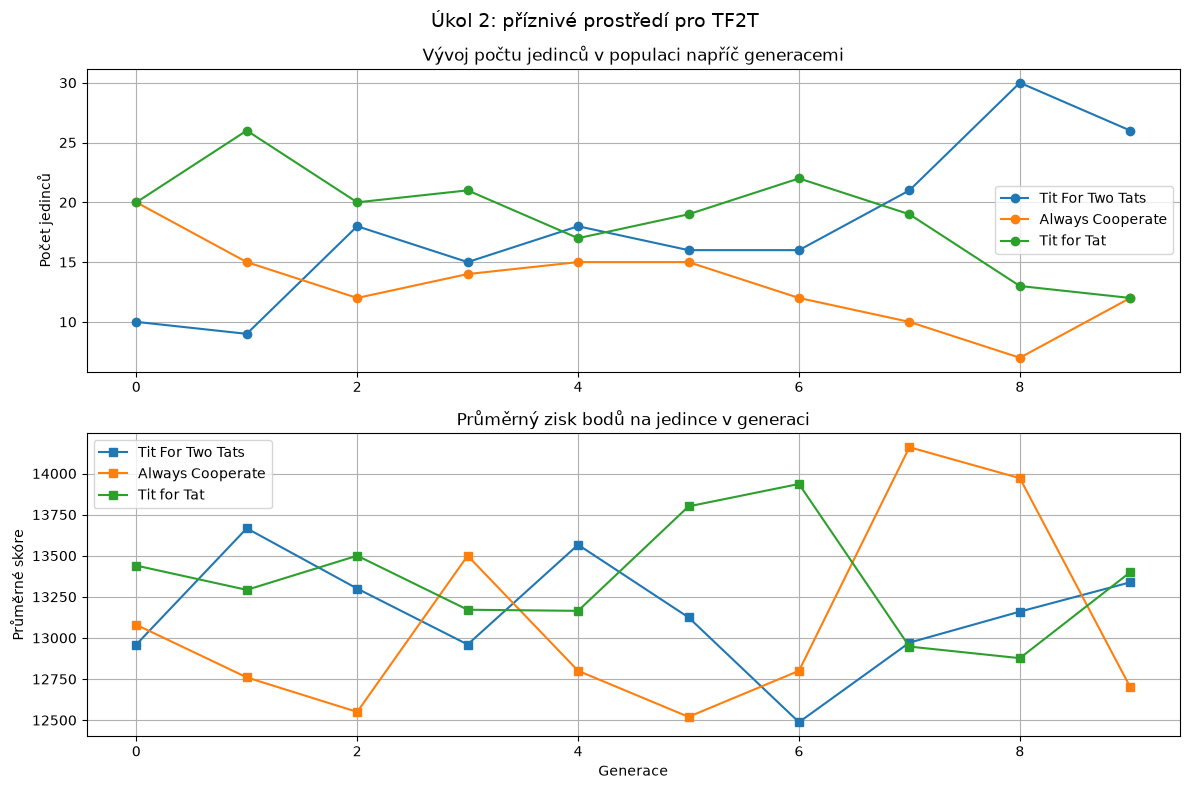

🧪 Testuji Nepříznivé prostředí pro TF2T...
Strategie                          Start   Gen 9  Konec    Prum. skore (gen 0 -> posl.)
Tit For Two Tats                      10       4      0              7920 -> 6900
Alternator (C, D, C, D, ...)          40      46     50             10520 -> 9513


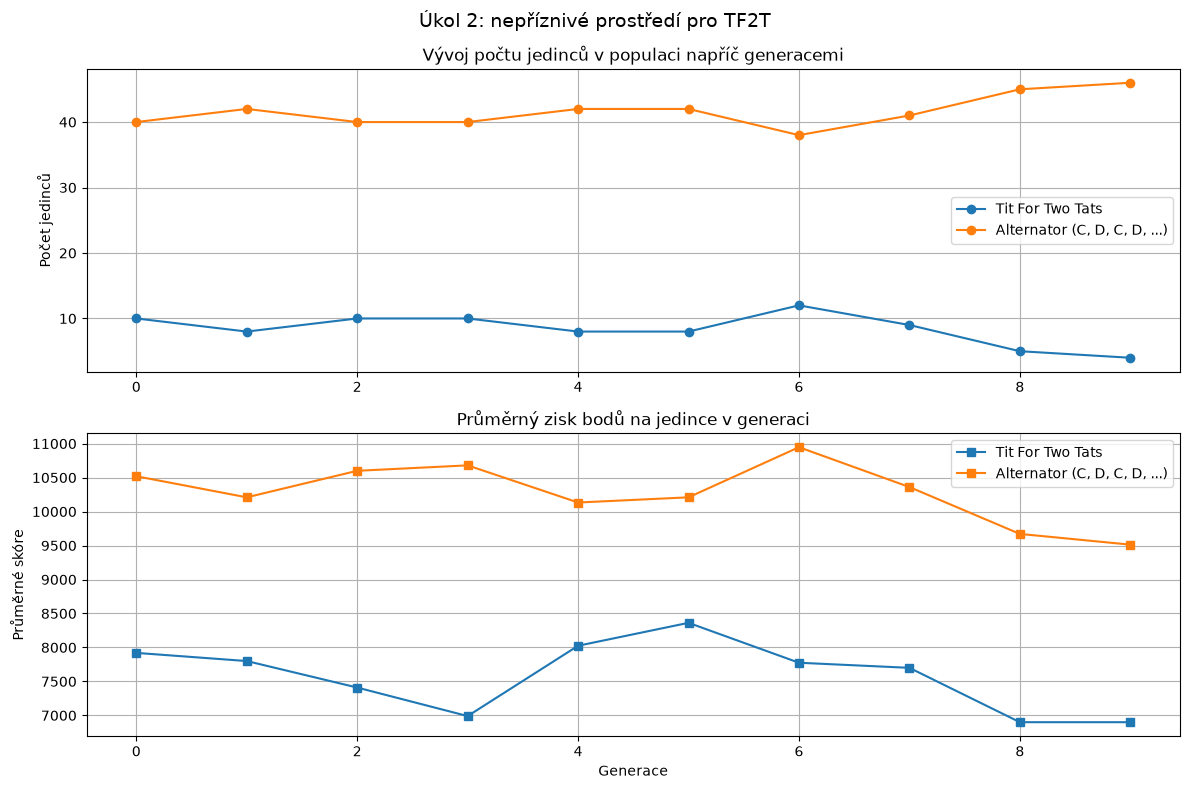

([{'strategies.titfortwotats': 10, 'strategies.alternator': 40},
  {'strategies.titfortwotats': 8, 'strategies.alternator': 42},
  {'strategies.titfortwotats': 10, 'strategies.alternator': 40},
  {'strategies.titfortwotats': 10, 'strategies.alternator': 40},
  {'strategies.titfortwotats': 8, 'strategies.alternator': 42},
  {'strategies.titfortwotats': 8, 'strategies.alternator': 42},
  {'strategies.titfortwotats': 12, 'strategies.alternator': 38},
  {'strategies.titfortwotats': 9, 'strategies.alternator': 41},
  {'strategies.titfortwotats': 5, 'strategies.alternator': 45},
  {'strategies.titfortwotats': 4, 'strategies.alternator': 46}],
 [{'strategies.titfortwotats': np.float64(7920.0),
   'strategies.alternator': np.float64(10520.0)},
  {'strategies.titfortwotats': np.float64(7800.0),
   'strategies.alternator': np.float64(10209.52380952381)},
  {'strategies.titfortwotats': np.float64(7410.0),
   'strategies.alternator': np.float64(10600.0)},
  {'strategies.titfortwotats': np.float64(

In [14]:
# [BUŇKA 5] ÚKOL 2 – Návrh TF2T a vyhledání stabilního vs. destruktivního prostředí

tf2t_code = """
class TitForTwoTats:
    @staticmethod
    def author_name(): return "Student"
    @staticmethod
    def strategy_name(): return "Tit For Two Tats"
    def __init__(self): self.reset()
    def reset(self): self.defects = 0
    def last_move(self, my, other):
        if other == 'D': self.defects += 1
        else: self.defects = 0
    def play(self):
        return 'D' if self.defects >= 2 else 'C'
def create_strategy(): return TitForTwoTats()
"""
with open('strategies/titfortwotats.py', 'w') as f:
    f.write(tf2t_code.strip())

# Příznivá populace: samí spolupracovníci, TF2T nikdo nezradí dvakrát po sobě
config_favorable = {
    'strategies.titfortwotats': 10,
    'strategies.always_cooperate': 20,
    'strategies.titfortat': 20
}
with open('config_fav.json', 'w') as f: json.dump(config_favorable, f)

print("🧪 Testuji Příznivé prostředí pro TF2T...")
run_simulation('config_fav.json', max_gen=10, seed=42, title='Úkol 2: příznivé prostředí pro TF2T')

# Nepříznivá populace: Alternator střídá C a D, takže TF2T nikdy neuvidí dvě zrady po sobě
# a nechá se vykořisťovat donekonečna (TF2T získá ~1.5 bodu za kolo, Alternator ~4)
alternator_code = """
class Alternator:
    @staticmethod
    def author_name(): return "Student"
    @staticmethod
    def strategy_name(): return "Alternator (C, D, C, D, ...)"
    def __init__(self): self.reset()
    def reset(self): self.next = 'C'
    def last_move(self, my, other): self.next = 'D' if my == 'C' else 'C'
    def play(self): return self.next
def create_strategy(): return Alternator()
"""
with open('strategies/alternator.py', 'w') as f:
    f.write(alternator_code.strip())

config_unfavorable = {
    'strategies.titfortwotats': 10,
    'strategies.alternator': 40
}
with open('config_unfav.json', 'w') as f: json.dump(config_unfavorable, f)

print("🧪 Testuji Nepříznivé prostředí pro TF2T...")
run_simulation('config_unfav.json', max_gen=10, seed=42, title='Úkol 2: nepříznivé prostředí pro TF2T')

---

### 📝 Úkol 3: Změna matice odměn – Je hra stále Vězňovým dilematem?

Vyzkoušejte, co se stane s dynamikou populace, pokud změníte matici odměn tak, že porušíte základní nerovnosti Vězňova dilematu ($T > R > P > S$).

Otestujte např. matici hry **Stag Hunt (Lov na jelena)**, kde platí $R > T > P > S$:

* $(C, C) \rightarrow (4, 4)$
* $(C, D) \rightarrow (0, 3)$
* $(D, C) \rightarrow (3, 0)$
* $(D, D) \rightarrow (1, 1)$

=== MATICE ODMĚN (Hráč 1 / Hráč 2) ===
C: 4/4 | 0/3
D: 3/0 | 1/1
🛡️ Minimax analýza pro Hráče 1:
   Akce 'C': Garantované minimum = 0 bodů
   Akce 'D': Garantované minimum = 1 bodů
   -> Minimax volba: 'D'

⚖️ Nalezené Nashovy rovnováhy (Hráč 1, Hráč 2):
   -> Profil: (C, C)
   -> Profil: (D, D)

🧪 Referenční běh se standardní maticí Vězňova dilematu...
Strategie                          Start   Gen 9  Konec    Prum. skore (gen 0 -> posl.)
Always Cooperate                      10       0      0              9873 -> 0
Always Defect                         10       0      0              8821 -> 0
Random                                10      11     10             11194 -> 11173
Tit for Tat                           10      30     37             10268 -> 12409
Tit For Two Tats                      10       9      3             11006 -> 11409


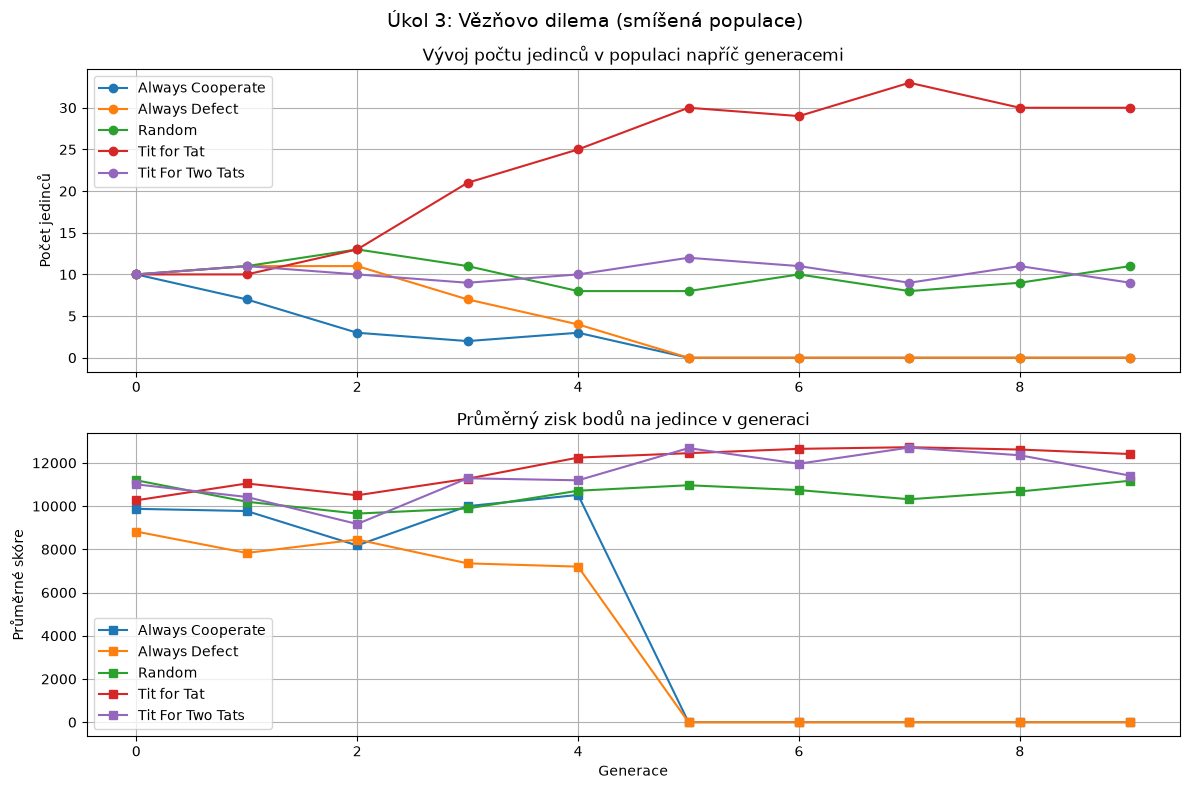

🧪 Spouštím simulaci s maticí Stag Hunt...
Strategie                          Start   Gen 9  Konec    Prum. skore (gen 0 -> posl.)
Always Cooperate                      10       0      0             13164 -> 0
Always Defect                         10       0      0              6501 -> 0
Random                                10       0      0              9922 -> 0
Tit for Tat                           10      20     20             12583 -> 17120
Tit For Two Tats                      10      30     30             13736 -> 17920


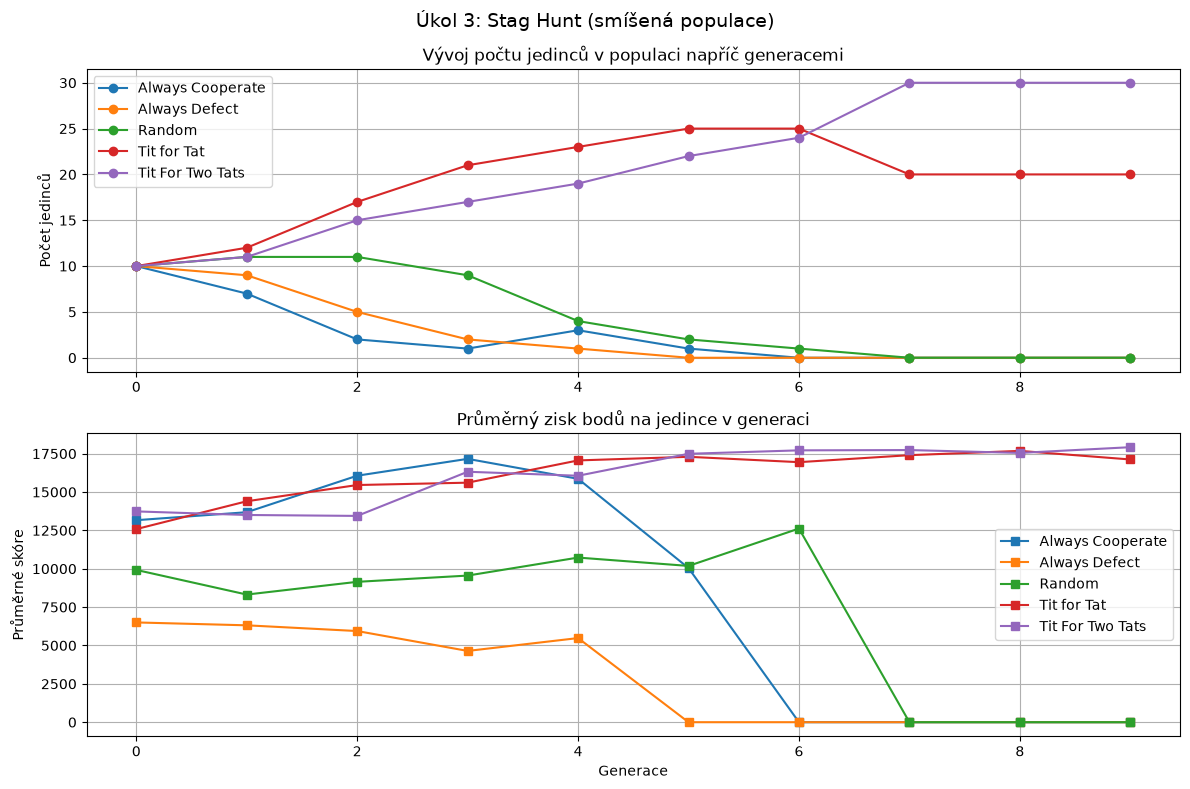

([{'strategies.always_cooperate': 10,
   'strategies.always_defect': 10,
   'strategies.random_strat': 10,
   'strategies.titfortat': 10,
   'strategies.titfortwotats': 10},
  {'strategies.always_cooperate': 7,
   'strategies.always_defect': 9,
   'strategies.random_strat': 11,
   'strategies.titfortat': 12,
   'strategies.titfortwotats': 11},
  {'strategies.always_cooperate': 2,
   'strategies.always_defect': 5,
   'strategies.random_strat': 11,
   'strategies.titfortat': 17,
   'strategies.titfortwotats': 15},
  {'strategies.always_cooperate': 1,
   'strategies.always_defect': 2,
   'strategies.random_strat': 9,
   'strategies.titfortat': 21,
   'strategies.titfortwotats': 17},
  {'strategies.always_cooperate': 3,
   'strategies.always_defect': 1,
   'strategies.random_strat': 4,
   'strategies.titfortat': 23,
   'strategies.titfortwotats': 19},
  {'strategies.always_cooperate': 1,
   'strategies.always_defect': 0,
   'strategies.random_strat': 2,
   'strategies.titfortat': 25,
   's

In [15]:
# [BUŇKA 6] ÚKOL 3 – Simulace s modifikovanou maticí odměn (Stag Hunt)

stag_hunt_matrix = {
    ('C', 'C'): (4, 4), # Odměna za společný lov jelena
    ('C', 'D'): (0, 3), # Hráč 1 utekl bez úlovku, Hráč 2 ulovil zajíce
    ('D', 'C'): (3, 0),
    ('D', 'D'): (1, 1)  # Obu ulovili malého zajíce
}

# Analýza jednorázové hry Stag Hunt nástrojem z Buňky 1
R1_sh = np.array([[4, 0],
                  [3, 1]])
R2_sh = np.array([[4, 3],
                  [0, 1]])
analyze_payoff_matrix(R1_sh, R2_sh)

# Stejná smíšená populace pro obě matice, aby šlo výsledky porovnat
config_mix = {
    'strategies.always_cooperate': 10,
    'strategies.always_defect': 10,
    'strategies.random_strat': 10,
    'strategies.titfortat': 10,
    'strategies.titfortwotats': 10
}
with open('config_mix.json', 'w') as f: json.dump(config_mix, f)

print("\n🧪 Referenční běh se standardní maticí Vězňova dilematu...")
run_simulation('config_mix.json', max_gen=10, seed=7, title='Úkol 3: Vězňovo dilema (smíšená populace)')

print("🧪 Spouštím simulaci s maticí Stag Hunt...")
run_simulation('config_mix.json', max_gen=10, custom_matrix=stag_hunt_matrix, seed=7, title='Úkol 3: Stag Hunt (smíšená populace)')

---

### 📝 Úkol 4: Návrh učící se / adaptivní strategie (Q-Learning)

Naimplementujte strategii `QLearningAgent`, která nepoužívá pevně daná pravidla, ale učí se odhadovat očekávanou hodnotu ($Q$-hodnotu) pro akce $C$ a $D$ na základě předchozího tahu soupeře (stavy: `'START'`, `'OPP_C'`, `'OPP_D'`).

Aktualizační pravidlo Q-učení:


$$Q(s, a) \leftarrow Q(s, a) + \alpha \cdot \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

In [16]:
# [BUŇKA 7] ÚKOL 4 – Implementace Q-Learning Agenta pro IPD
q_learning_code = """
import random
import numpy as np

class QLearningAgent:
    @staticmethod
    def author_name(): return "Student AI"
    @staticmethod
    def strategy_name(): return "Q-Learning Agent"

    def __init__(self, alpha=0.1, gamma=0.9, epsilon=0.1):
        self.alpha = alpha     # Rychlost učení
        self.gamma = gamma     # Diskontní faktor
        self.epsilon = epsilon # Míra průzkumu (exploration)
        # Stavy: 'START', 'C', 'D' (předchozí tah soupeře)
        # Akce: 0 = 'C', 1 = 'D'
        # Q-tabulka vzniká jen jednou, aby si agent naučené hodnoty přenášel mezi zápasy a generacemi
        self.q_table = {
            'START': [3.0, 3.0],
            'C': [3.0, 3.0],
            'D': [1.0, 1.0]
        }
        # Výchozí odměny Vězňova dilematu, simulátor je přepíše přes set_reward_matrix()
        self.reward_map = {('C','C'):3, ('C','D'):0, ('D','C'):5, ('D','D'):1}
        self.reset()

    def set_reward_matrix(self, matrix):
        # Odměny se berou z matice, se kterou běží simulace (např. Stag Hunt)
        self.reward_map = {moves: rewards[0] for moves, rewards in matrix.items()}

    def reset(self):
        # Na začátku zápasu se resetuje jen stav, ne naučené Q-hodnoty
        self.current_state = 'START'
        self.last_action_idx = None

    def last_move(self, my_move, other_move):
        r = self.reward_map.get((my_move, other_move), 0)

        next_state = other_move

        # Q-Learning update
        if self.last_action_idx is not None:
            old_q = self.q_table[self.current_state][self.last_action_idx]
            max_future_q = max(self.q_table[next_state])
            new_q = old_q + self.alpha * (r + self.gamma * max_future_q - old_q)
            self.q_table[self.current_state][self.last_action_idx] = new_q

        self.current_state = next_state

    def play(self):
        # Epsilon-greedy výběr akce
        if random.random() < self.epsilon:
            action_idx = random.choice([0, 1])
        else:
            q_vals = self.q_table[self.current_state]
            action_idx = int(np.argmax(q_vals))

        self.last_action_idx = action_idx
        return 'C' if action_idx == 0 else 'D'

def create_strategy(): return QLearningAgent()
"""

with open('strategies/q_learning.py', 'w') as f:
    f.write(q_learning_code.strip())

# Varianta s rychlejším učením a menším průzkumem pro porovnání parametrů
q_learning_fast_code = """
from strategies.q_learning import QLearningAgent

class FastQLearningAgent(QLearningAgent):
    @staticmethod
    def strategy_name(): return "Q-Learning (alpha=0.5, eps=0.02)"

def create_strategy(): return FastQLearningAgent(alpha=0.5, epsilon=0.02)
"""

with open('strategies/q_learning_fast.py', 'w') as f:
    f.write(q_learning_fast_code.strip())

print("✅ Úkol 4: Q-Learning strategie vytvořena a uložena do 'strategies/q_learning.py'.")
print("✅ Varianta s alpha=0.5, epsilon=0.02 uložena do 'strategies/q_learning_fast.py'.")

✅ Úkol 4: Q-Learning strategie vytvořena a uložena do 'strategies/q_learning.py'.
✅ Varianta s alpha=0.5, epsilon=0.02 uložena do 'strategies/q_learning_fast.py'.


#### Experimenty s Q-Learning agentem

1. **Experiment A:** Q-Learning agent (výchozí parametry $\alpha=0.1, \gamma=0.9, \epsilon=0.1$) ve smíšené populaci se všemi základními strategiemi.
2. **Experiment B:** Porovnání výchozího agenta s rychleji se učící variantou ($\alpha=0.5, \epsilon=0.02$) v populaci TFT a AD.

Po každém běhu vypisujeme naučenou Q-tabulku (sdílená instance strategie, která se učí napříč zápasy i generacemi).

🧪 Experiment A: Q-Learning ve smíšené populaci...
Strategie                          Start  Gen 14  Konec    Prum. skore (gen 0 -> posl.)
Q-Learning Agent                      10       1      0              9404 -> 13034
Always Cooperate                      10       5      6              9206 -> 14089
Always Defect                         10       0      0              9212 -> 0
Tit for Tat                           10       2      1             10414 -> 12600
Tit For Two Tats                      10      42     43             10403 -> 13074


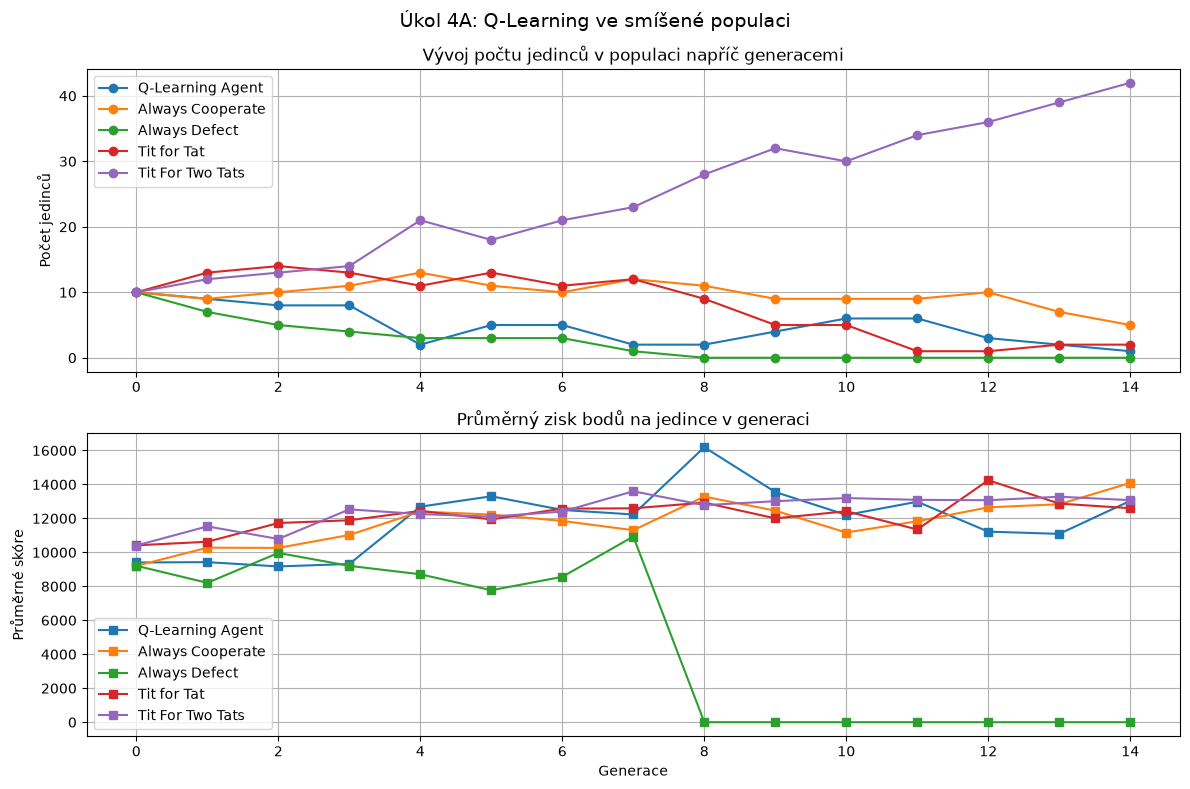

Naučená Q-tabulka – Q-Learning Agent:
   stav START  Q(C) =  27.11   Q(D) =  33.63   -> volí D
   stav C      Q(C) =  30.00   Q(D) =  29.77   -> volí C
   stav D      Q(C) =  27.61   Q(D) =  27.09   -> volí C

🧪 Experiment B: vliv parametrů alpha a epsilon...
Strategie                          Start  Gen 14  Konec    Prum. skore (gen 0 -> posl.)
Q-Learning Agent                      10       0      0              5096 -> 0
Q-Learning (alpha=0.5, eps=0.02)      10       0      0              6450 -> 0
Tit for Tat                           15      50     50              8119 -> 13200
Always Defect                         15       0      0              4525 -> 0


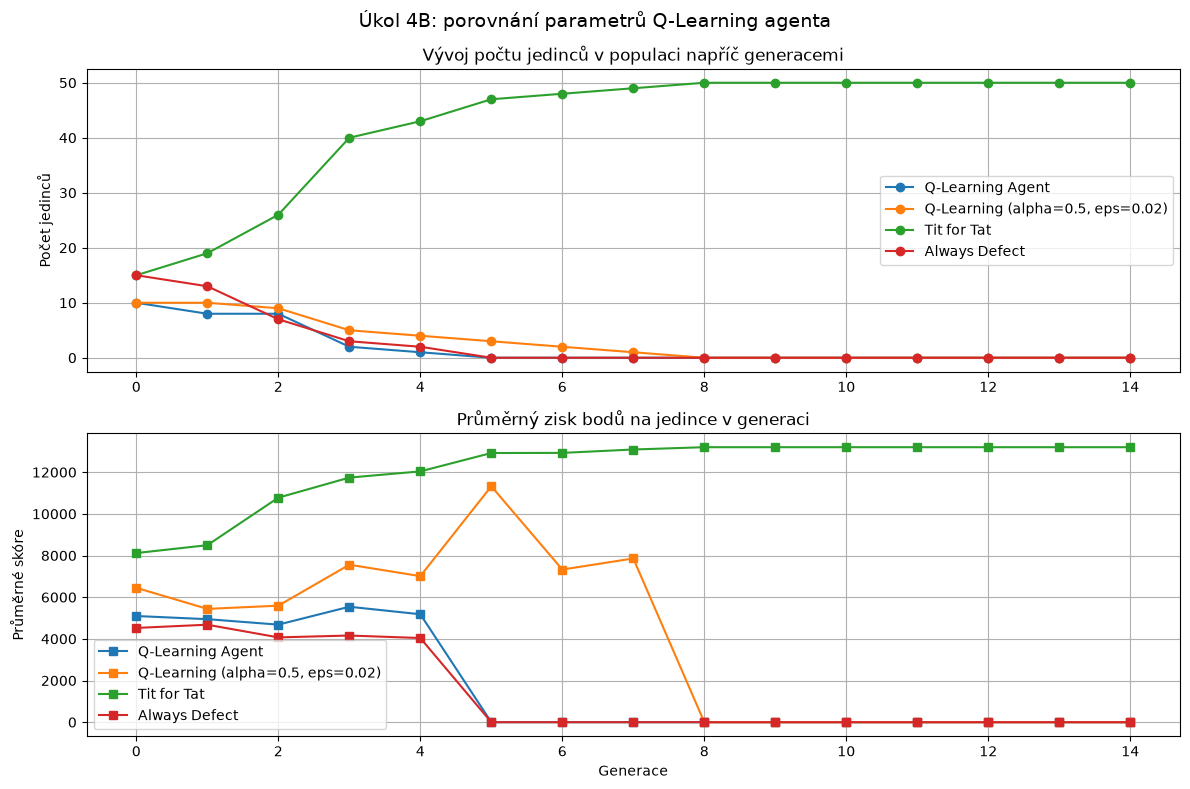

Naučená Q-tabulka – Q-Learning Agent:
   stav START  Q(C) =  11.80   Q(D) =  15.91   -> volí D
   stav C      Q(C) =  11.24   Q(D) =  12.69   -> volí D
   stav D      Q(C) =  11.34   Q(D) =  11.79   -> volí D
Naučená Q-tabulka – Q-Learning (alpha=0.5, eps=0.02):
   stav START  Q(C) =  21.85   Q(D) =  16.16   -> volí C
   stav C      Q(C) =  23.72   Q(D) =  23.55   -> volí C
   stav D      Q(C) =   9.55   Q(D) =  11.26   -> volí D



In [17]:
# [BUŇKA 8] ÚKOL 4 – Q-Learning agent v evoluční simulaci

def print_q_tables(strategies):
    for k, s in strategies.items():
        if hasattr(s, 'q_table'):
            print(f"Naučená Q-tabulka – {s.strategy_name()}:")
            for state, (q_c, q_d) in s.q_table.items():
                best = 'C' if q_c >= q_d else 'D'
                print(f"   stav {state:<6} Q(C) = {q_c:6.2f}   Q(D) = {q_d:6.2f}   -> volí {best}")
    print()

config_q_mix = {
    'strategies.q_learning': 10,
    'strategies.always_cooperate': 10,
    'strategies.always_defect': 10,
    'strategies.titfortat': 10,
    'strategies.titfortwotats': 10
}
with open('config_q_mix.json', 'w') as f: json.dump(config_q_mix, f)

print("🧪 Experiment A: Q-Learning ve smíšené populaci...")
_, _, strats_a = run_simulation('config_q_mix.json', max_gen=15, seed=1, title='Úkol 4A: Q-Learning ve smíšené populaci')
print_q_tables(strats_a)

config_q_params = {
    'strategies.q_learning': 10,
    'strategies.q_learning_fast': 10,
    'strategies.titfortat': 15,
    'strategies.always_defect': 15
}
with open('config_q_params.json', 'w') as f: json.dump(config_q_params, f)

print("🧪 Experiment B: vliv parametrů alpha a epsilon...")
_, _, strats_b = run_simulation('config_q_params.json', max_gen=15, seed=1, title='Úkol 4B: porovnání parametrů Q-Learning agenta')
print_q_tables(strats_b)

---

## 5. Analytické otázky a Sebereflexe

Vyplňte odpovědi do textových polí níže:

### ❓ Analytické otázky

1. **Nashova rovnováha vs. Evoluční stabilita:**
* Vysvětlete na základě výsledků ze **Scénáře A** a **Scénáře B** v Úkolu 1, proč strategie `Always Cooperate` není evolučně stabilní (ESS), zatímco `Always Defect` a `Tit for Tat` dokážou invazi čelit.
* *Odpověď:*

**Nejnáročnější prostředí:**
* Pro **TF2T** to byla populace s `Alternator` (střídá C, D, C, D…). TF2T nikdy neuvidí dvě zrady po sobě, takže se nechá vykořisťovat celý zápas (~1,5 bodu za kolo oproti ~4 u Alternatoru) a vymřela z 10 na 0 jedinců. V příznivé populaci (AC + TFT) přitom vyhrála (10 → 30).
* Pro **Q-Learning agenta** to byla populace TFT + AD. Na začátku ho převaha zrádců naučí zrazovat, ale jakmile AD vymřou, TFT ho za to trestá. To je přesně problém **nestacionárního prostředí** v multiagentních systémech.

**Hlavní poznatky:**
1. Spolupráce přežije jen tehdy, když je podmíněná a umí oplácet (TFT odolal invazi, AC ne).
2. Neexistuje univerzálně nejlepší strategie, úspěch závisí na složení populace (TF2T vyhrála v příznivém prostředí i ve Stag Hunt, ale Alternator ji zlikvidoval).
3. Struktura matice odměn mění dominantní strategie i počet Nashových rovnováh, a tím celou dynamiku populace.
4. U učícího se agenta výsledek zásadně ovlivňují $\alpha$, $\epsilon$ a reprezentace stavu.
5. Simulace jsou stochastické, proto jsem nastavil seed, aby výsledky šly zopakovat a ověřit.

Původní kód měl dvě chyby, které jsem opravil. `reset()` mazal Q-tabulku před **každým zápasem**, takže agent si nic nepřenášel mezi zápasy. Odměny byly napevno z Vězňova dilematu, takže při Stag Hunt by se učil ze špatné matice. Teď se Q-tabulka vytváří jen v `__init__` a odměny bere ze simulátoru přes `set_reward_matrix()`. Simulátor používá jednu sdílenou instanci strategie, takže se tabulka učí napříč zápasy i generacemi.

* **Experiment A (smíšená populace):** agent měl v generaci 0 průměrné skóre jen **9 404** (náhodné tahy, zrádci v populaci). Díky učení se skóre zvedlo až na **13 034**, ale počet jedinců klesal (10 → 1 → 0), protože populaci mezitím ovládla TF2T (43). Naučil se spolupracovat po spolupráci soupeře (stav `C` → `C`), ale na začátku zápasu zrazuje (`START` → `D`). To ho proti TFT/TF2T stojí odvetu a k tomu 10 % náhodných tahů ($\epsilon = 0.1$).
* **Experiment B (TFT + AD, porovnání parametrů):** výchozí agent ($\alpha = 0.1, \epsilon = 0.1$) se pod vlivem zrádců na začátku naučil **zrazovat ve všech stavech** a pak ho TFT trestal. Varianta ($\alpha = 0.5, \epsilon = 0.02$) měla v generaci 0 vyšší skóre (**6 450 vs. 5 096**). Naučila se podmíněnou spolupráci ($C$ po $C$, $D$ po $D$, tedy prakticky TFT), ale vymřela také, protože TFT ovládl populaci dříve, než se tabulka stihla ustálit.

**Úprava parametrů:** vyšší $\alpha$ (0.3–0.5), aby agent rychleji reagoval na převládající typ oponenta. Nižší $\epsilon$, nebo spíš **postupně klesající $\epsilon$** (např. z 0.2 na 0.01), protože průzkumné zrady vůči TFT/TF2T vyvolávají odvetu. Pomohlo by i rozšířit stav o poslední tahy obou hráčů (4 stavy místo 3), aby agent poznal, zda soupeř oplácí.

Po změně na $R = 4 > T = 3 > P = 1 > S = 0$ **přestala být zrada dominantní akcí**. Proti soupeři, který hraje $C$, je lepší $C$ (4 > 3), a proti soupeři, který hraje $D$, je lepší $D$ (1 > 0). Nejlepší odpověď tedy závisí na soupeři. Analýza z Buňky 1 to potvrzuje: hra má **dvě ryzí Nashovy rovnováhy, $(C, C)$ a $(D, D)$**. Minimax stále volí $D$ (garantované minimum 1), ale to už je jen „bezpečná“ rovnováha, ne optimální.

V simulaci jsem použil stejnou smíšenou populaci (10× AC, AD, Random, TFT, TF2T) a stejný seed pro obě matice:
* **Vězňovo dilema:** AD i AC vymřeli, vyhrál TFT (37 jedinců), přežil Random (10) a TF2T (3).
* **Stag Hunt:** vymřeli AD, AC **i Random**, populaci ovládly reciproční strategie TF2T (30) a TFT (20). Průměrné skóre vzrostlo na ~17 900 a ~17 100 bodů (v PD ~12 400).

Zrada se ve Stag Hunt vyplácí výrazně méně (pokušení $T$ je menší než odměna za spolupráci), takže populace rychleji konverguje k sociálně optimální rovnováze $(C, C)$. Tolerantní TF2T si vedla lépe než TFT, protože nereaguje na ojedinělé náhodné zrady a neztrácí body zbytečnou odvetou.

Minimax předpokládá, že soupeř je **čistý protivník**, který se snaží minimalizovat můj zisk (hra s nulovým součtem, nejhorší možný případ). V matici Vězňova dilematu proto zvolí $D$, protože garantované minimum je 1 > 0. Agent řízený Minimaxem se tak v každém kole chová jako `Always Defect`.

Iterované Vězňovo dilema je ale hra s **nenulovým součtem**: oba hráči mohou spoluprací získat $R = 3$ za kolo, tedy 600 bodů za zápas. Minimax neuvažuje opakování hry, reputaci, budoucí odvetu ani možnost, že soupeř spolupracuje. Proti TFT proto Minimax/AD získá jen ~204 bodů místo 600 a proti dalším zrádcům 200. V simulacích to bylo vidět přímo: ve Scénáři B a v referenčním běhu Úkolu 3 strategie AD **vymřela**. Minimax tedy chrání před nejhorším případem, ale vzdává se globálně nejlepšího (Pareto optimálního) výsledku $(C, C)$.

Ve **Scénáři A** (45× AC + 5× AD) měli zrádci v generaci 0 průměrně **20 120 bodů**, spolupracovníci jen **11 920**. AD proti AC bere v každém kole $T = 5$, zatímco AC dostává $S = 0$. Ruletová selekce proto zvýhodnila AD a už v generaci 9 bylo v populaci **50× AD a 0× AC**. `Always Cooperate` není ESS: invazní mutant (AD) má proti AC vyšší zisk než AC samo proti sobě ($T = 5 > R = 3$) a AC nemá žádný mechanismus odvety. Profil $(C, C)$ navíc není ani Nashova rovnováha jednorázové hry, protože jednostranná odchylka na $D$ se vždy vyplatí.

`Always Defect` je ESS, protože $(D, D)$ je jediná Nashova rovnováha. Mutant AC v populaci AD dostává $S = 0 < P = 1$ a mutant TFT ztratí první kolo (199 vs. 200 bodů za zápas), takže se neprosadí.

Ve **Scénáři B** (45× TFT + 5× AD) ztratí TFT proti AD jen první kolo a pak oplácí, takže AD z jednoho zápasu s TFT získá jen ~204 bodů. Dvojice TFT–TFT ale získá 600 bodů. Průměrné skóre v generaci 0 bylo **TFT 12 358 vs. AD 4 359**, AD vymřeli a populace skončila na **50× TFT**. TFT invazi odolá díky reciprocitě: zrádce nikdy nezíská víc, než kolik TFT získají spoluprací mezi sebou. (TFT není striktní ESS vůči AC: v populaci TFT se AC chová stejně a může se šířit neutrálním driftem, což je vidět i v Úkolu 2.)


2. **Aplikace Minimaxu v multiagentním prostředí:**
* Proč selhává Minimax algoritmus při snaze o dosažení globálně nejvyššího skóre v iterovaném Vězňově dilematu? S jakým předpokladem Minimax pracuje a proč tento předpoklad vede v IPD k podoptimálním výsledkům?
* *Odpověď:*


3. **Vliv modifikace matice odměn (Stag Hunt):**
* Jak se změnila dominanta strategií po úpravě matice v Úkolu 3 na odměny $R=4, T=3$? Byla volba zrady ($D$) stále dominantní akcí?
* *Odpověď:*



---

### 📝 Sebereflexe studenta

1. **Adaptabilita Q-Learning Agenta:**
* Jak se vámi naimplementovaný `QLearningAgent` vyvíjel během generací? Jaké parametry ($\alpha, \epsilon$) byste upravili, aby agent rychleji reagoval na převládající typ oponenta?
* *Odpověď:* Náš QLearningAgent měl na začátku nízké skóre, protože jeho Q-tabulka ještě nebyla naučená a v populaci bylo hodně zrádců. Během generací se jeho průměrné skóre zlepšilo (z 9 404 na 13 034), naučil se spolupracovat, když soupeř spolupracoval, ale na začátku zápasu zrazoval, za což ho TFT a TF2T trestali, takže v populaci nakonec vymřel. Proti převaze TFT a AD se výchozí agent dokonce naučil zrazovat ve všech stavech. Protože stav obsahuje jen poslední tah soupeře, agent nedokáže rozlišit TFT od naivně spolupracujícího hráče. Aby reagoval rychleji, zvýšili bychom rychlost učení α (nové zkušenosti by víc přepisovaly staré Q-hodnoty) a místo pevného ε = 0,1 bychom nechali ε postupně klesat, ale ne úplně na nulu, aby si všiml, když se složení oponentů změní. Diskontní faktor γ bychom naopak nesnižovali, protože krátkozraký agent v iterovaném dilematu víc zrazuje. Pomohlo by i rozšířit stav o vlastní poslední tah.


2. **Závěrečné zhodnocení:**
* Které prostředí (mix strategií) bylo pro vámi navržené agenty nejnáročnější a jaké hlavní poznatky si z dnešního laboratoře odnášíte?
* *Odpověď:*Nejnáročnější pro Q-learning agenta bylo prostředí s TFT a Always Defect (experiment B): na začátku převažovali zrádci, takže se agent naučil zrazovat, ale jakmile zrádci vymřeli, TFT ho za stejné chování trestal a agent se nestihl přeučit, takže vymřel. Pro TF2T bylo nejnáročnější prostředí s Alternatorem, který střídá C a D, takže TF2T nikdy nevidí dvě zrady po sobě a nechá se vykořisťovat. Hlavní poznatek je, že úspěch strategie silně závisí na složení populace, že spolupráce se vyplácí jen tehdy, když ji ostatní opětují, a že učící se agent potřebuje dobře nastavenou rovnováhu mezi učením a zkoumáním, aby se dokázal přizpůsobit měnícím se oponentům.



### 🔧 Provedené úpravy kódu

* **Buňka 3 (simulátor):** bez `custom_matrix` se vždy použije standardní matice. Dřív zůstala matice Stag Hunt nastavená i pro všechny další běhy. Přibyl parametr `seed` pro reprodukovatelnost, `title` pro graf, textový souhrn výsledků a předání matice odměn učícím se strategiím (`set_reward_matrix`). Moduly strategií se znovu načítají (`importlib.reload`), aby se změny projevily bez restartu kernelu.
* **Buňka 5 (Úkol 2):** doplněna nepříznivá populace s novou strategií `Alternator` (`strategies/alternator.py`).
* **Buňka 6 (Úkol 3):** explicitní smíšená populace místo `config.json` (jeho obsah závisel na tom, jaké soubory zrovna byly ve složce `strategies/`). Přidán referenční běh s maticí Vězňova dilematu a analýza Nashových rovnováh Stag Hunt.
* **Buňka 7 (Úkol 4):** Q-tabulka se už nemaže před každým zápasem a odměny se berou z aktuální matice. Přidána varianta `strategies/q_learning_fast.py` ($\alpha = 0.5, \epsilon = 0.02$).
* **Buňka 8 (nová):** experimenty s Q-Learning agentem v evoluční simulaci a výpis naučených Q-tabulek.
* V teoretické části opraven překlep ve vzorci Nashovy rovnováhy pro Hráče 2: $R_2(a_1^*, a_2^*) \ge R_2(a_1^*, a_2)$.

---

> **Pokyny k odevzdání:** Uložte vyplněný notebook (`File -> Download -> Download .ipynb`) a odevzdejte jej společně se složkou vytvořených modulů strategií v archivu `.zip` do odevzdávárny v informačním systému.